# 06 · Parameter sweeps: detuning and tweezer phase

Two sweeps that show how to explore a parameter with levisim, and what to check while doing it:

1. the cavity detuning, for one particle moving in $x$ and $y$: the optical spring moves the peaks,
   and there is a best detuning for cooling, which the textbook weak-coupling formulas predict;
2. the optical phase of the second of two tweezers: the cavity-mediated coupling between the
   particles changes character with the phase, and over a window of phases one collective mode is
   anti-damped, so the system has no steady state - the instability met in
   [`01_quickstart_cavity_spectra`](01_quickstart_cavity_spectra.ipynb).

**Runtime:** about 40 s. **Background:** [Conventions](../../docs/concepts/conventions.md) (sign of
$\Delta$, the couplings $G_{j_n} = g_{j_n}e^{i\phi_n}$) and
[Spectra of several particles in one cavity](../../docs/guide/cavity_spectra.md).

In [1]:
import os
os.environ.setdefault('TQDM_DISABLE', '1')

import contextlib
import io
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from levisim.analysis.gaussian_states import mean_phonon_numbers
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.units import kHz, degrees
from levisim.multiphysics.covariance import dimension_covariance, steady_state_covariance
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.utils.shelf import DEFAULT_cavity_kwargs, DEFAULT_gas_kwargs

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL

def quietly(function, *args, **kwargs):
    # build a MultiTrap or call a spectrum function without levisim's progress messages
    with contextlib.redirect_stdout(io.StringIO()):
        return function(*args, **kwargs)

## 1. Detuning

One particle from the physical defaults, moving in $x$ and $y$; the cavity detuning
$\Delta = \omega_\text{tw} - \omega_\text{c}$ runs from $-100$ to $-900$ kHz (red detuning; the default is
$-450$ kHz). For each detuning, compute the homodyne spectrum and the steady-state occupations.

In [2]:
ω_range = np.arange(120, 170, 0.1) * kHz
detunings = -np.arange(100, 901, 25) * kHz   # includes the default, -450 kHz
S_hh, occupations = [], []
for Δ in detunings:
    mt = quietly(MultiTrap, num_traps=1, Cartesian_axes_per_trap=2, gas_kwargs=DEFAULT_gas_kwargs,
                 cavity_kwargs=dict(DEFAULT_cavity_kwargs, Δ=Δ), ω_range=ω_range)
    S_hh.append(quietly(mt.homodyne_spectrum, LAM))
    V = steady_state_covariance(mt)            # raises if any detuning were unstable
    occupations.append(mean_phonon_numbers(dimension_covariance(mt, V, ['x1', 'y1'])))
S_hh, occupations = np.array(S_hh), np.array(occupations)
dims = mt.dimensions
κ = mt.cavity.κ
print(f'κ/2π = {κ / kHz:.1f} kHz; Ω_x/2π = {dims["x1"].Ω / kHz:.2f} kHz, Ω_y/2π = {dims["y1"].Ω / kHz:.2f} kHz;'
      f' {len(detunings)} detunings, all stable')

κ/2π = 390.4 kHz; Ω_x/2π = 156.34 kHz, Ω_y/2π = 135.80 kHz; 33 detunings, all stable


The weak-coupling (textbook) predictions for one motion of frequency $\Omega$ and coupling $G$ use
the anti-Stokes and Stokes scattering rates $A_\mp = |G|^2\kappa/[(\Delta \pm \Omega)^2 + \kappa^2/4]$:
optical damping $\Gamma_\text{opt} = A_- - A_+$, optical spring
$\delta\Omega = |G|^2\{(\Delta + \Omega)/[(\Delta + \Omega)^2 + \kappa^2/4] + (\Delta - \Omega)/[(\Delta - \Omega)^2 + \kappa^2/4]\}$,
and occupation $n = (\Gamma n_\text{th} + A_+)/(\Gamma + \Gamma_\text{opt})$.

x1: largest predicted spring shift -2.14 kHz at Δ/2π = -325 kHz
y1: largest predicted spring shift -2.52 kHz at Δ/2π = -300 kHz
x1: fewest phonons 15.4 at Δ/2π = -175 kHz (weak coupling: 12.8 at -175 kHz); at the default -450 kHz: 54.0
y1: fewest phonons 12.5 at Δ/2π = -175 kHz (weak coupling: 13.9 at -175 kHz); at the default -450 kHz: 43.7


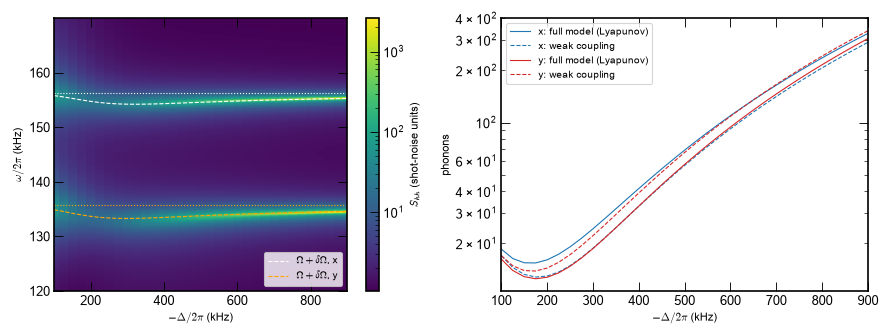

In [3]:
def weak_coupling(dim, Δ):
    G2, Ω = abs(dim.G)**2, dim.Ω
    A_minus = G2 * κ / ((Δ + Ω)**2 + κ**2 / 4)
    A_plus = G2 * κ / ((Δ - Ω)**2 + κ**2 / 4)
    δΩ = G2 * ((Δ + Ω) / ((Δ + Ω)**2 + κ**2 / 4) + (Δ - Ω) / ((Δ - Ω)**2 + κ**2 / 4))
    n = (dim.Γ * dim.noise_phonons_exact + A_plus) / (dim.Γ + A_minus - A_plus)
    return δΩ, n

f, d = ω_range / kHz, -detunings / kHz
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
mesh = ax1.pcolormesh(d, f, S_hh.T, norm=LogNorm(), cmap='viridis', shading='auto')
fig.colorbar(mesh, ax=ax1, label=r'$S_{hh}$ (shot-noise units)')
for label, colour in (('x1', 'w'), ('y1', 'orange')):
    shift = np.array([weak_coupling(dims[label], Δ)[0] for Δ in detunings])
    ax1.plot(d, (dims[label].Ω + shift) / kHz, '--', color=colour, lw=1, label=f'$\\Omega + \\delta\\Omega$, {label[0]}')
    ax1.axhline(dims[label].Ω / kHz, color=colour, ls=':', lw=1)
ax1.set_xlim(d[0], d[-1])
ax1.set_xlabel(r'$-\Delta / 2\pi$ (kHz)')
ax1.set_ylabel(r'$\omega / 2\pi$ (kHz)')
ax1.legend(fontsize=9, loc='lower right')

for ii, (label, colour) in enumerate((('x1', 'tab:blue'), ('y1', 'tab:red'))):
    ax2.semilogy(d, occupations[:, ii], color=colour, label=f'{label[0]}: full model (Lyapunov)')
    ax2.semilogy(d, [weak_coupling(dims[label], Δ)[1] for Δ in detunings], '--', color=colour, lw=1, label=f'{label[0]}: weak coupling')
ax2.set_xlim(d[0], d[-1])
ax2.set_xlabel(r'$-\Delta / 2\pi$ (kHz)')
ax2.set_ylabel('phonons')
ax2.legend(fontsize=9, loc='upper left')
fig.tight_layout()

for ii, label in enumerate(('x1', 'y1')):
    shifts = np.array([weak_coupling(dims[label], Δ)[0] for Δ in detunings])
    print(f'{label}: largest predicted spring shift {shifts.min() / kHz:.2f} kHz at Δ/2π = {detunings[np.argmin(shifts)] / kHz:.0f} kHz')
for ii, label in enumerate(('x1', 'y1')):
    best = np.argmin(occupations[:, ii])
    formula = np.array([weak_coupling(dims[label], Δ)[1] for Δ in detunings])
    print(f'{label}: fewest phonons {occupations[best, ii]:.1f} at Δ/2π = {detunings[best] / kHz:.0f} kHz'
          f' (weak coupling: {formula.min():.1f} at {detunings[np.argmin(formula)] / kHz:.0f} kHz);'
          f' at the default -450 kHz: {occupations[np.argmin(np.abs(detunings + 450 * kHz)), ii]:.1f}')

Dotted lines: bare trap frequencies; dashed: the weak-coupling optical spring. The peaks follow the
predicted spring shift, which is largest, $-2.1$ kHz ($x$) and $-2.5$ kHz ($y$), around $|\Delta|/2\pi = 300$ kHz.
Cooling is best much closer to resonance than the default detuning: at $|\Delta|/2\pi \approx$ 160-180 kHz
the motions reach 12-15 phonons, against 54 ($x$) and 44 ($y$) at the default $-450$ kHz. Here the sidebands are not resolved ($\kappa/2\pi = 390$ kHz is larger than $\Omega$), so
the optimum is not at $\Delta = -\Omega$. The weak-coupling formula follows the full model closely
but not exactly: the exact calculation also includes the cavity-mediated $x$-$y$ coupling and the
coupling beyond second order.

## 2. Tweezer phase

Two particles, each moving in $x$ and $y$. `MultiTrap` builds physical systems with fixed tweezer
phases (0° and 90°), so to sweep the phase, copy the physical parameters into a toy-parameter
system and set $\phi_2$ freely:

In [4]:
physical = quietly(MultiTrap, num_traps=2, Cartesian_axes_per_trap=2, gas_kwargs=DEFAULT_gas_kwargs,
                   cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=np.array([0.0]))

def with_second_tweezer_phase(φ2, ω_range=np.array([0.0])):
    # the physical 2×2 system, with every parameter copied into toy_params and φ2 set freely
    dims = physical.dimensions
    toy_params = dict(
        Ω_model='custom', toy_Ωjn_dict={label: dim.Ω for label, dim in dims.items()},
        use_Γ_formula=False, Γjn_dict={label: dim.Γ for label, dim in dims.items()},
        gjn_dict={label: dim.g for label, dim in dims.items()},
        φn_dict={1: physical.φn_dict[1], 2: φ2},
        T=physical.gas.T, m=dims['x1'].m,
    )
    return quietly(MultiTrap, num_traps=2, Cartesian_axes_per_trap=2, toy_params=toy_params,
                   gas_kwargs=DEFAULT_gas_kwargs, cavity_kwargs=DEFAULT_cavity_kwargs, ω_range=ω_range)

copy = with_second_tweezer_phase(physical.φn_dict[2])
print(f'physical φ2 = {np.degrees(physical.φn_dict[2]):.0f}°; copy reproduces the drift matrix to'
      f' {np.max(np.abs(copy.drift_matrix - physical.drift_matrix)) / np.max(np.abs(physical.drift_matrix)):.0e} (relative)')

physical φ2 = 90°; copy reproduces the drift matrix to 3e-35 (relative)


(The only difference is the physical system's intra-particle coupling $g_{xy} \approx 10^{-29}$ rad/s at the
node, which the copy sets to zero.) Now sweep $\phi_2$ from 0° to 180°, recording the homodyne
spectrum and the largest real part of the drift-matrix eigenvalues - positive means a growing mode:

unstable for φ2 in (54°, 126°) on this 3° grid; largest growth rate 2678 /s at φ2 = 90°
φ2 =   0°: largest Re λ =   -259.9 /s
φ2 =  30°: largest Re λ =   -294.0 /s
φ2 =  90°: largest Re λ =  +2677.5 /s


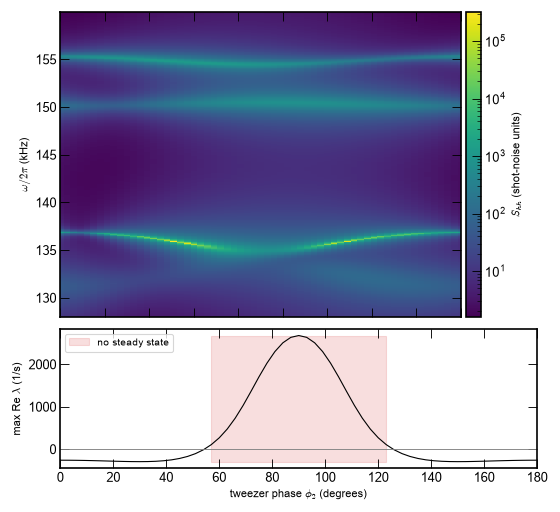

In [5]:
phases = np.arange(0, 180.1, 3) * degrees
ω_range = np.arange(128, 160, 0.08) * kHz
S_phase, growth = [], []
for φ2 in phases:
    mt = with_second_tweezer_phase(φ2, ω_range)
    S_phase.append(quietly(mt.homodyne_spectrum, LAM))
    growth.append(np.max(np.linalg.eigvals(mt.drift_matrix).real))
S_phase, growth = np.array(S_phase), np.array(growth)
unstable = growth > 0
edges = np.degrees(phases[np.flatnonzero(np.diff(unstable.astype(int)))])
print(f'unstable for φ2 in ({edges[0]:.0f}°, {edges[1] + 3:.0f}°) on this 3° grid;'
      f' largest growth rate {growth.max():.0f} /s at φ2 = {np.degrees(phases[np.argmax(growth)]):.0f}°')
for φ in (0, 30, 90):
    k = np.argmin(np.abs(phases - φ * degrees))
    print(f'φ2 = {φ:3d}°: largest Re λ = {growth[k]:+8.1f} /s')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6.4), sharex=True, height_ratios=(2.2, 1))
p, f = np.degrees(phases), ω_range / kHz
mesh = ax1.pcolormesh(p, f, S_phase.T, norm=LogNorm(), cmap='viridis', shading='auto')
fig.colorbar(mesh, ax=ax1, label=r'$S_{hh}$ (shot-noise units)', pad=0.01)
ax1.set_ylabel(r'$\omega / 2\pi$ (kHz)')
ax2.plot(p, growth, 'k')
ax2.axhline(0, color='grey', lw=0.8)
ax2.fill_between(p, growth.min(), growth.max(), where=unstable, color='tab:red', alpha=0.15, label='no steady state')
ax2.set_xlim(p[0], p[-1])
ax2.set_xlabel(r'tweezer phase $\phi_2$ (degrees)')
ax2.set_ylabel(r'max Re $\lambda$ (1/s)')
ax2.legend(fontsize=9, loc='upper left')
fig.tight_layout()

With equal phases both particles couple to the same light quadrature, and the cavity sees only the
bright combinations of the motions. As $\phi_2$ grows, the light force each particle exerts on the
other picks up a component in the other quadrature, and the coupling between the near-degenerate
$y$ motions (1.8 kHz apart, closer than their optical damping) stops being reciprocal. For $\phi_2$
between about 50° and 130° one collective $y$ mode then gains energy faster than the cavity removes
it. The spectrum (top) shows nothing unusual there - a growing mode has a Lorentzian of the same
shape as a decaying one - which is why a stability check belongs in any sweep:
`steady_state_covariance` raises for unstable systems, and the eigenvalues of `mtrap.drift_matrix`
show which mode is at fault. The default physical system, at $\phi_2 = 90°$, sits in the middle of
the unstable window. (This is the linearised model: a real system would leave the linear regime,
and the sign and size of the effect depend on the coupling phases being right.)